<a href="https://colab.research.google.com/github/reyagrace777/MST_Hackathon/blob/main/ARIMA_Airline_Forecasting.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import itertools
import warnings
warnings.filterwarnings("ignore")

from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.stattools import adfuller
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.stats.diagnostic import acorr_ljungbox
from sklearn.metrics import mean_squared_error, mean_absolute_error


In [2]:
data = [112,118,132,129,121,135,148,148,136,119,104,118,
        115,126,141,135,125,149,170,170,158,133,114,140,
        145,150,178,163,172,178,199,199,184,162,146,166,
        171,180,193,181,183,218,230,242,209,191,172,194,
        196,196,236,235,229,243,264,272,237,211,180,201,
        204,188,235,227,234,264,302,293,259,229,203,229,
        242,233,267,269,270,315,364,347,312,274,237,278,
        284,277,317,313,318,374,413,405,355,306,271,306,
        315,301,356,348,355,422,465,467,404,347,305,336,
        340,318,362,348,363,435,491,505,404,359,310,337,
        360,342,406,396,420,472,548,559,463,407,362,405,
        417,391,419,461,472,535,622,606,508,461,390,432]

dates = pd.date_range(start="1949-01-01", periods=144, freq="MS")
df = pd.DataFrame({"Passengers": data}, index=dates)
df.index.name = "Month"


In [3]:
print(df.head())
df.info()
print(df.describe())
print(df.isnull().sum())


            Passengers
Month                 
1949-01-01         112
1949-02-01         118
1949-03-01         132
1949-04-01         129
1949-05-01         121
<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 144 entries, 1949-01-01 to 1960-12-01
Freq: MS
Data columns (total 1 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   Passengers  144 non-null    int64
dtypes: int64(1)
memory usage: 2.2 KB
       Passengers
count  144.000000
mean   280.298611
std    119.966317
min    104.000000
25%    180.000000
50%    265.500000
75%    360.500000
max    622.000000
Passengers    0
dtype: int64


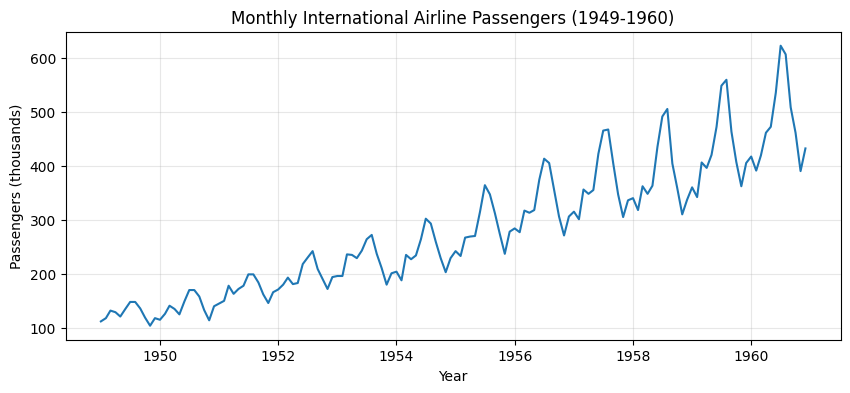

In [4]:
plt.figure(figsize=(10, 4))
plt.plot(df.index, df["Passengers"], color="tab:blue")
plt.title("Monthly International Airline Passengers (1949-1960)")
plt.xlabel("Year")
plt.ylabel("Passengers (thousands)")
plt.grid(True, alpha=0.3)
plt.show()


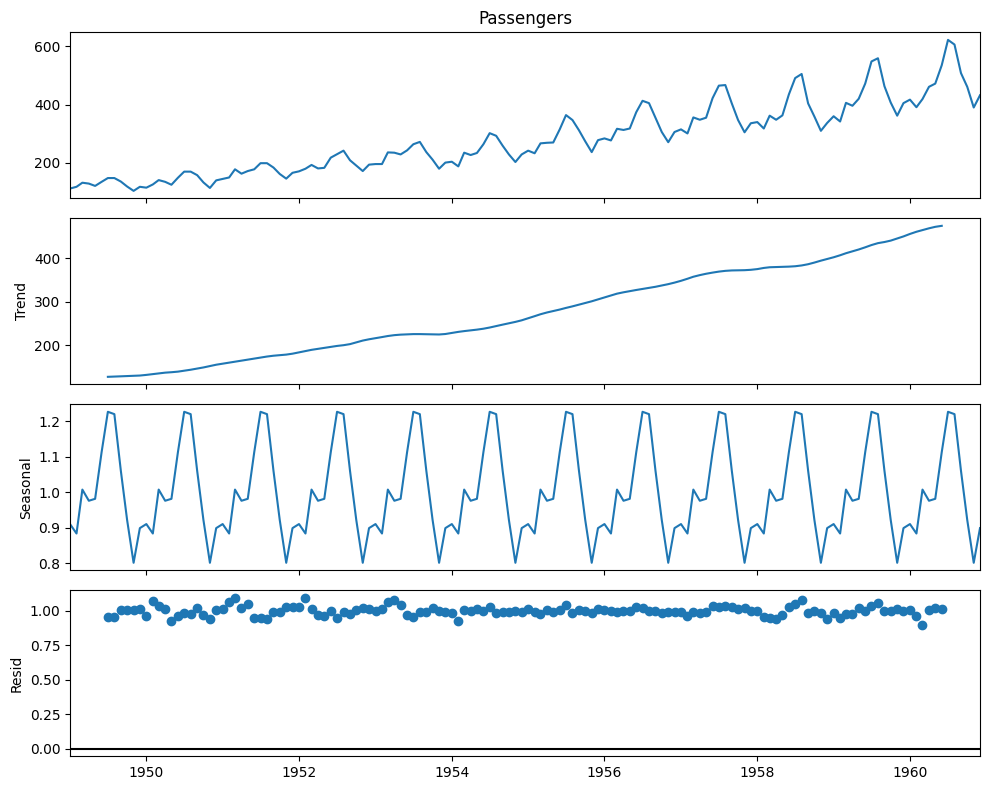

In [5]:
decomp = seasonal_decompose(df["Passengers"], model="multiplicative", period=12)
fig = decomp.plot()
fig.set_size_inches(10, 8)
plt.tight_layout()
plt.show()


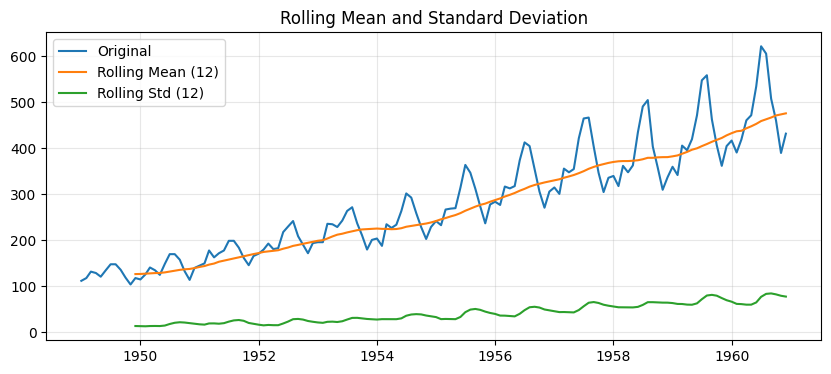

In [6]:
rolmean = df["Passengers"].rolling(window=12).mean()
rolstd = df["Passengers"].rolling(window=12).std()

plt.figure(figsize=(10, 4))
plt.plot(df["Passengers"], label="Original")
plt.plot(rolmean, label="Rolling Mean (12)")
plt.plot(rolstd, label="Rolling Std (12)")
plt.legend(loc="upper left")
plt.title("Rolling Mean and Standard Deviation")
plt.grid(True, alpha=0.3)
plt.show()


In [7]:
def adf_test(series, title=""):
    result = adfuller(series.dropna(), autolag="AIC")
    print(f"ADF Test on {title}")
    print("ADF Statistic :", round(result[0], 4))
    print("p-value       :", round(result[1], 4))
    print("Lags used     :", result[2])
    print("Critical Values:")
    for key, value in result[4].items():
        print(f"   {key} : {round(value, 4)}")
    if result[1] <= 0.05:
        print("Conclusion: Series is STATIONARY (reject H0)")
    else:
        print("Conclusion: Series is NON-STATIONARY (fail to reject H0)")

adf_test(df["Passengers"], "Original Series")


ADF Test on Original Series
ADF Statistic : 0.8154
p-value       : 0.9919
Lags used     : 13
Critical Values:
   1% : -3.4817
   5% : -2.884
   10% : -2.5788
Conclusion: Series is NON-STATIONARY (fail to reject H0)


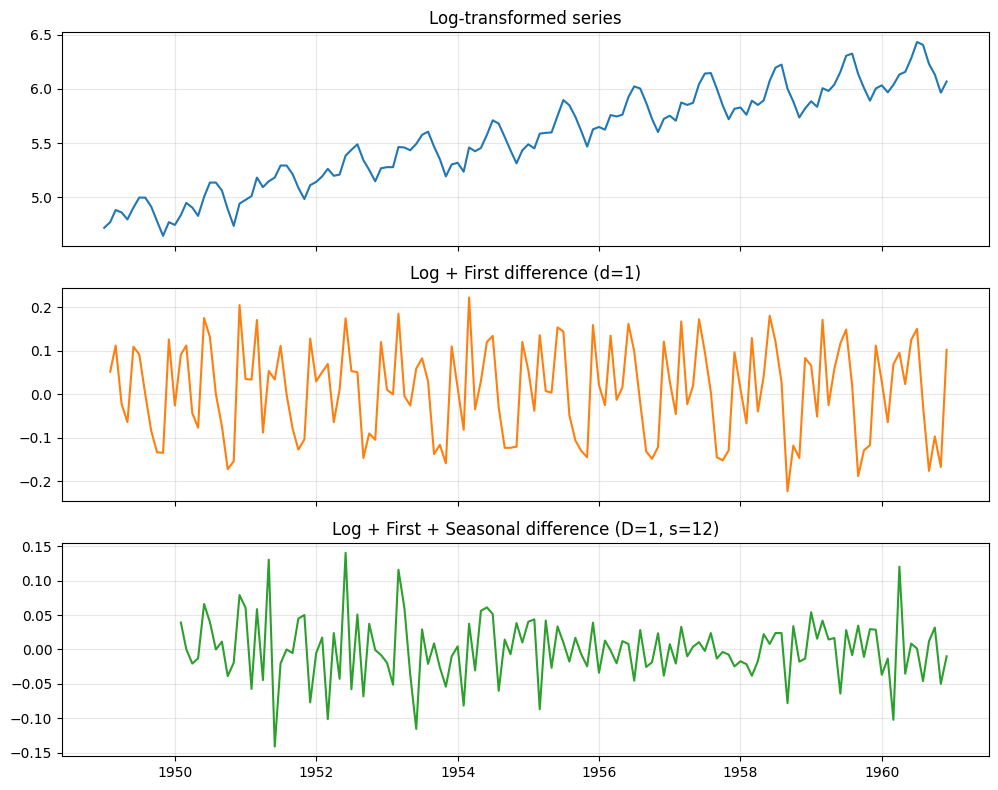

In [8]:
df["Log"] = np.log(df["Passengers"])
df["Log_Diff"] = df["Log"].diff()
df["Log_Diff_Seasonal"] = df["Log_Diff"].diff(12)

fig, ax = plt.subplots(3, 1, figsize=(10, 8), sharex=True)
ax[0].plot(df["Log"])
ax[0].set_title("Log-transformed series")
ax[1].plot(df["Log_Diff"], color="tab:orange")
ax[1].set_title("Log + First difference (d=1)")
ax[2].plot(df["Log_Diff_Seasonal"], color="tab:green")
ax[2].set_title("Log + First + Seasonal difference (D=1, s=12)")
for a in ax:
    a.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


In [9]:
adf_test(df["Log"], "Log Series")
adf_test(df["Log_Diff"], "Log + First Difference")
adf_test(df["Log_Diff_Seasonal"], "Log + First + Seasonal Difference")


ADF Test on Log Series
ADF Statistic : -1.717
p-value       : 0.4224
Lags used     : 13
Critical Values:
   1% : -3.4817
   5% : -2.884
   10% : -2.5788
Conclusion: Series is NON-STATIONARY (fail to reject H0)
ADF Test on Log + First Difference
ADF Statistic : -2.7171
p-value       : 0.0711
Lags used     : 14
Critical Values:
   1% : -3.4825
   5% : -2.8844
   10% : -2.579
Conclusion: Series is NON-STATIONARY (fail to reject H0)
ADF Test on Log + First + Seasonal Difference
ADF Statistic : -4.4433
p-value       : 0.0002
Lags used     : 12
Critical Values:
   1% : -3.487
   5% : -2.8864
   10% : -2.58
Conclusion: Series is STATIONARY (reject H0)


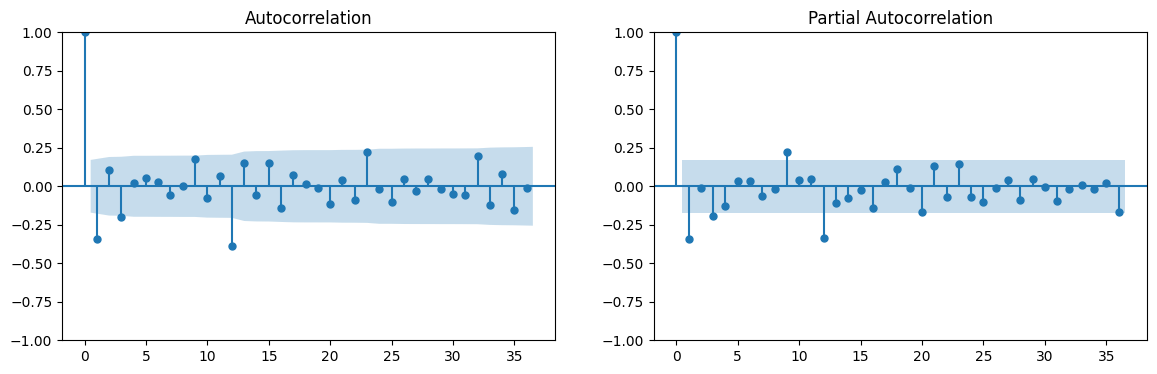

In [10]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
plot_acf(df["Log_Diff_Seasonal"].dropna(), lags=36, ax=ax[0])
plot_pacf(df["Log_Diff_Seasonal"].dropna(), lags=36, ax=ax[1], method="ywm")
plt.show()


In [11]:
train = df["Log"].iloc[:-24]
test = df["Log"].iloc[-24:]

print("Total observations :", len(df))
print("Training set       :", len(train), "->",
      train.index[0].strftime("%b %Y"), "to", train.index[-1].strftime("%b %Y"))
print("Testing set        :", len(test), "->",
      test.index[0].strftime("%b %Y"), "to", test.index[-1].strftime("%b %Y"))


Total observations : 144
Training set       : 120 -> Jan 1949 to Dec 1958
Testing set        : 24 -> Jan 1959 to Dec 1960


In [12]:
results = []
for p, d, q in itertools.product(range(0, 4), [1], range(0, 4)):
    try:
        fit = ARIMA(train, order=(p, d, q)).fit()
        results.append((p, d, q, fit.aic))
    except Exception:
        continue

res_df = pd.DataFrame(results, columns=["p", "d", "q", "AIC"])
res_df = res_df.sort_values("AIC").reset_index(drop=True)
print(res_df.head(5).to_string(index=False))

best_order = tuple(res_df.loc[0, ["p", "d", "q"]].astype(int))
print("Best ARIMA order:", best_order, "| AIC:", round(res_df.loc[0, "AIC"], 2))


 p  d  q         AIC
 3  1  3 -226.596192
 2  1  1 -208.368189
 3  1  2 -207.695845
 3  1  1 -206.982100
 1  1  2 -206.861324
Best ARIMA order: (3, 1, 3) | AIC: -226.6


/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/statespace/mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(


In [13]:
arima_model = ARIMA(train, order=best_order).fit()
print(arima_model.summary())


                               SARIMAX Results                                
Dep. Variable:                    Log   No. Observations:                  120
Model:                 ARIMA(3, 1, 3)   Log Likelihood                 120.298
Date:                Thu, 05 Nov 2026   AIC                           -226.596
Time:                        13:21:11   BIC                           -207.142
Sample:                    01-01-1949   HQIC                          -218.697
                         - 12-01-1958                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          0.7147      0.088      8.124      0.000       0.542       0.887
ar.L2          0.6426      0.127      5.059      0.000       0.394       0.891
ar.L3         -0.8366      0.086     -9.771      0.0

/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/statespace/mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(


In [14]:
sarima_model = SARIMAX(train,
                       order=(0, 1, 1),
                       seasonal_order=(0, 1, 1, 12)).fit(disp=False)
print(sarima_model.summary())


                                     SARIMAX Results                                      
Dep. Variable:                                Log   No. Observations:                  120
Model:             SARIMAX(0, 1, 1)x(0, 1, 1, 12)   Log Likelihood                 197.505
Date:                            Thu, 05 Nov 2026   AIC                           -389.010
Time:                                    13:22:05   BIC                           -380.991
Sample:                                01-01-1949   HQIC                          -385.759
                                     - 12-01-1958                                         
Covariance Type:                              opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ma.L1         -0.3425      0.087     -3.924      0.000      -0.514      -0.171
ma.S.L12      -0.5406      0.105   

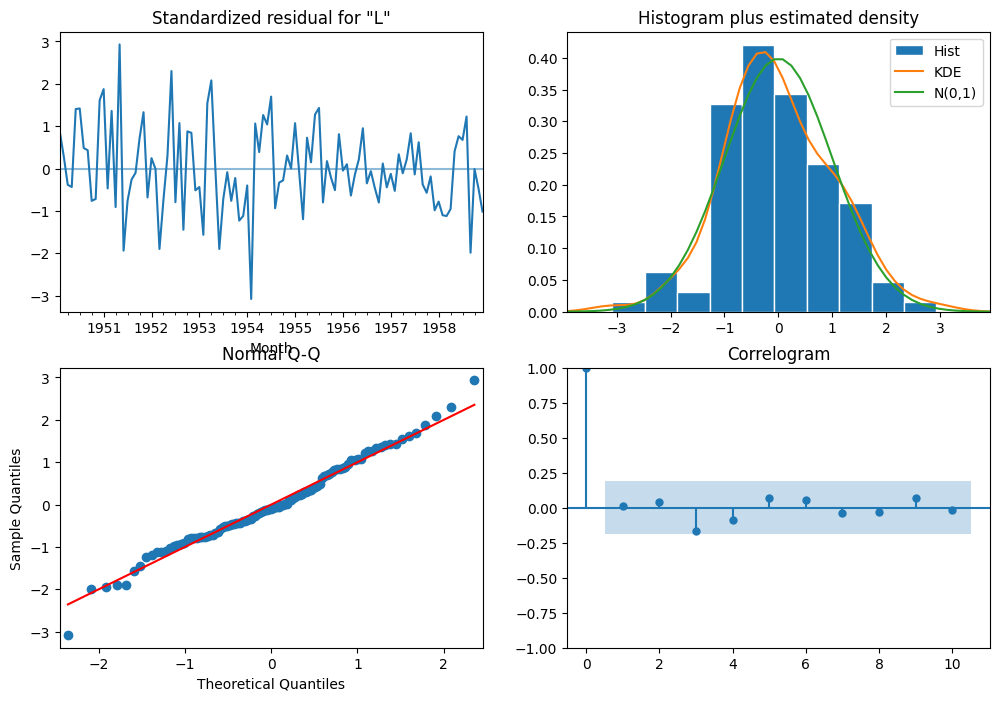

      lb_stat  lb_pvalue
12  22.474451   0.032534
24  22.653447   0.540325


In [15]:
sarima_model.plot_diagnostics(figsize=(12, 8))
plt.show()

print(acorr_ljungbox(sarima_model.resid, lags=[12, 24], return_df=True))


ARIMA    RMSE =   92.51 | MAE =   70.82 | MAPE = 14.12%
SARIMA   RMSE =   43.18 | MAE =   39.44 | MAPE =  8.51%


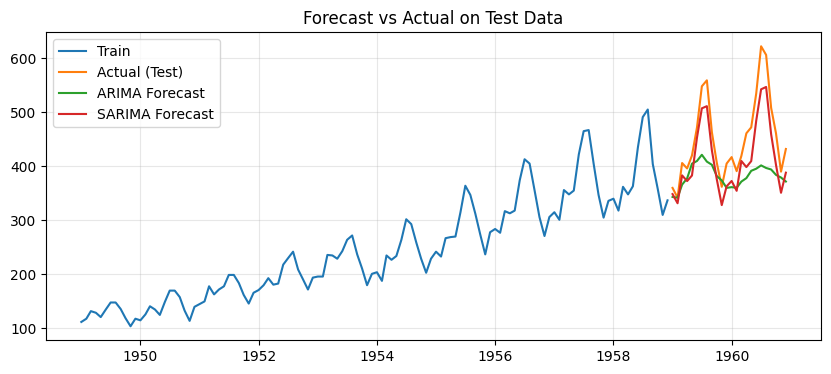

In [16]:
# forecast 24 months (log scale) and convert back with exp()
arima_pred = np.exp(arima_model.get_forecast(steps=24).predicted_mean)
sarima_pred = np.exp(sarima_model.get_forecast(steps=24).predicted_mean)
actual = np.exp(test)

def evaluate(actual, pred, name):
    rmse = np.sqrt(mean_squared_error(actual, pred))
    mae = mean_absolute_error(actual, pred)
    mape = np.mean(np.abs((actual - pred) / actual)) * 100
    print(f"{name:8s} RMSE = {rmse:7.2f} | MAE = {mae:7.2f} | MAPE = {mape:5.2f}%")

evaluate(actual, arima_pred, "ARIMA")
evaluate(actual, sarima_pred, "SARIMA")

plt.figure(figsize=(10, 4))
plt.plot(np.exp(train), label="Train")
plt.plot(actual, label="Actual (Test)")
plt.plot(arima_pred, label="ARIMA Forecast")
plt.plot(sarima_pred, label="SARIMA Forecast")
plt.legend(loc="upper left")
plt.title("Forecast vs Actual on Test Data")
plt.grid(True, alpha=0.3)
plt.show()


1961-01-01    450.0
1961-02-01    426.0
1961-03-01    479.0
1961-04-01    492.0
1961-05-01    509.0
1961-06-01    583.0
1961-07-01    670.0
1961-08-01    667.0
1961-09-01    558.0
1961-10-01    497.0
1961-11-01    430.0
1961-12-01    477.0
Freq: MS, Name: predicted_mean, dtype: float64


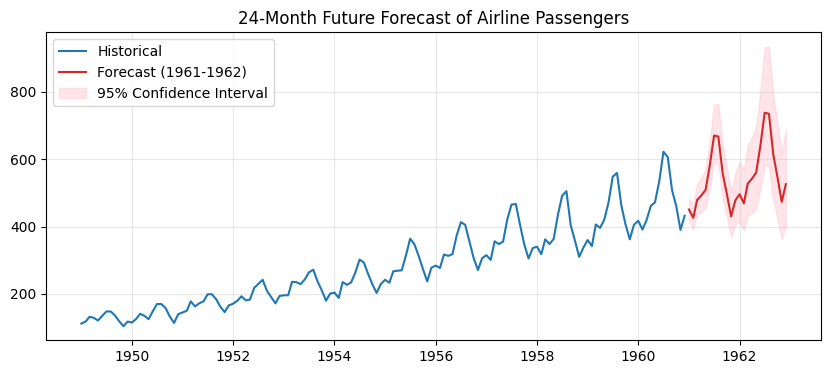

In [17]:
final_model = SARIMAX(df["Log"],
                      order=(0, 1, 1),
                      seasonal_order=(0, 1, 1, 12)).fit(disp=False)

future = final_model.get_forecast(steps=24)
future_mean = np.exp(future.predicted_mean)
future_ci = np.exp(future.conf_int())

print(future_mean.round(0).head(12))

plt.figure(figsize=(10, 4))
plt.plot(df["Passengers"], label="Historical")
plt.plot(future_mean, label="Forecast (1961-1962)", color="tab:red")
plt.fill_between(future_ci.index, future_ci.iloc[:, 0], future_ci.iloc[:, 1],
                 color="pink", alpha=0.4, label="95% Confidence Interval")
plt.legend(loc="upper left")
plt.title("24-Month Future Forecast of Airline Passengers")
plt.grid(True, alpha=0.3)
plt.show()
